# Groepsproject Olink — Part 3: Multiple testing (Python)

**Doel:** onderzoeken welke plasma-eiwitten een verschillende **Day 0 → Day 7**-verandering na influenza-vaccinatie vertonen bij **Young Adults** versus **Older Adults**.

Dit notebook is **onafhankelijk van de Part 2 RMarkdown** en leest rechtstreeks de drie originele CSV-bestanden in. Het gebruikt een gepaarde analyse: iedere donor levert een Day 0- en een Day 7-meting.

### Statistisch idee

Per eiwit en donor berekenen we `delta_NPX = NPX_Day7 − NPX_Day0`. Voor ieder eiwit testen we vervolgens met een multivariabel lineair model:

`delta_NPX ~ age_group + sex + cmv_status + baseline_batch + batch_changed`

- **H0**: het leeftijdscoëfficiënt voor `Older Adult` versus `Young Adult` is 0 (geen leeftijdsverschil in verandering).
- **H1**: het leeftijdscoëfficiënt verschilt van 0.
- Donoren zijn na het nemen van verschillen onafhankelijke observaties; we doen **geen** pseudoreplicatie van de 184 rijen.
- Voor alle geteste eiwitten corrigeren we de p-waarden met **Benjamini–Hochberg (FDR)**.

*Let op:* dit is een verdedigbaar **alternatief** voor het mixed-effects-model van Part 2, maar is niet exact hetzelfde model. Stem de covariaten en filters nadien af met je groep. De keuze van de technische covariaten is een vereenvoudiging: er wisselen bij sommige donoren batches tussen de twee bezoeken. Een sensitiviteitsanalyse kan later nodig zijn.

## Stap 1 — Imports en bestandspaden

Leg de drie CSV-bestanden in dezelfde map als deze notebook of in een submap `data/` (eventueel één map hoger in `data/`). De code herkent ook de suffix `(1)` of `(2)` in bestandsnamen. Bewaar liefst **één versie** van elke dataset in jullie GitHub-project om vergissingen te vermijden.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid")


def find_csv(prefix):
    """Zoek data in een gebruikelijke GitHub/Jupyter-mappenstructuur."""
    folders = [Path('.'), Path('data'), Path('../data'), Path('/mnt/data')]
    matches = []
    for folder in folders:
        matches.extend(sorted(folder.glob(f'{prefix}*.csv')))
    if not matches:
        raise FileNotFoundError(f"Kan {prefix}*.csv niet vinden. Plaats het in dezelfde map of in data/.")
    return matches[0]

paths = {
    'metadata': find_csv('sample_metadata'),
    'npx': find_csv('proteins_npx_raw'),
    'annotation': find_csv('protein_annotation'),
}
print('Gevonden bestanden:')
for key, path in paths.items():
    print(f'  {key}: {path}')

metadata = pd.read_csv(paths['metadata'])
npx = pd.read_csv(paths['npx'])
annotation = pd.read_csv(paths['annotation'])

print('\nAfmetingen:')
print('Metadata:', metadata.shape)
print('NPX:     ', npx.shape)
print('Annotatie:', annotation.shape)

Gevonden bestanden:
  metadata: sample_metadata.csv
  npx: proteins_npx_raw(1).csv
  annotation: protein_annotation(1).csv

Afmetingen:
Metadata: (867, 76)
NPX:      (867, 1482)
Annotatie: (1481, 12)


## Stap 2 — Dubbele eiwitnamen (zelfde Olink-ID) samenvoegen

De annotatie heeft **1.481 eiwitkolommen**, maar slechts **1.472 unieke Olink-ID's**: er zijn 9 paren alias-namen voor dezelfde assay. We selecteren per Olink-ID de naam met de minste ontbrekende waarden en vullen die aan vanuit het alias. Daarna verwijderen we het alias, zodat we geen identieke assay dubbel toetsen.

In [2]:
# Kies per Olink-ID één naam met de minste missings.
annotation_unique = (
    annotation.sort_values(['n_missing', 'protein'])
    .drop_duplicates(subset='olink_id', keep='first')
    .copy()
)

npx_clean = npx.copy()
for olink_id, group in annotation.groupby('olink_id'):
    if len(group) <= 1:
        continue
    main_name = annotation_unique.loc[
        annotation_unique['olink_id'] == olink_id, 'protein'
    ].iloc[0]
    for other_name in group['protein']:
        if other_name != main_name:
            npx_clean[main_name] = npx_clean[main_name].combine_first(npx_clean[other_name])
            npx_clean = npx_clean.drop(columns=other_name)

protein_columns = annotation_unique['protein'].tolist()
assert set(protein_columns) == set(npx_clean.columns) - {'sample_kit_id'}
print('Aantal unieke eiwitten na alias-consolidatie:', len(protein_columns))
print('NPX matrix:', npx_clean.shape)

Aantal unieke eiwitten na alias-consolidatie: 1472
NPX matrix: (867, 1473)


## Stap 3 — Kwaliteitsfilter *vóór* de hypothesetesten

De opdracht vraagt om oninformatieve features te verwijderen zonder de groepslabels te gebruiken. We kiezen **vooraf** twee technische filters:

- Maximaal **20% ontbrekende waarden** per eiwit (op de totale opgeschoonde matrix).
- Maximaal **50% onder de detectielimiet** volgens de Olink-annotatie.

Die grenzen zijn een praktische, verdedigbare **startkeuze**, geen officiële drempels uit de opdracht. Schrijf de gekozen criteria en het aantal overgebleven eiwitten in het verslag. Verander de drempels niet achteraf op basis van de p-waarden.

In [3]:
missing_fraction = npx_clean[protein_columns].isna().mean()
max_missing = 0.20    # maximaal 20% NA
max_below_lod = 50.0  # pct_below_lod is in procenten (0 - 100)

quality = annotation_unique[['protein', 'olink_id', 'pct_below_lod']].copy()
quality['missing_fraction'] = quality['protein'].map(missing_fraction)
quality['keep'] = (
    (quality['missing_fraction'] <= max_missing) &
    (quality['pct_below_lod'] <= max_below_lod)
)
selected_proteins = quality.loc[quality['keep'], 'protein'].tolist()

print('Unieke eiwitten vóór filter:', len(protein_columns))
print('Verwijderd door kwaliteitsfilter:', len(protein_columns) - len(selected_proteins))
print('Eiwitten voor statistische analyse:', len(selected_proteins))
assert len(selected_proteins) >= 20, 'De opdracht vereist minstens 20 features.'

Unieke eiwitten vóór filter: 1472
Verwijderd door kwaliteitsfilter: 150
Eiwitten voor statistische analyse: 1322


## Stap 4 — Selecteer Flu Year 1 Day 0 en Day 7

We nemen alleen de eerste vaccinatiereeks, net zoals het voorstel voor Part 2. Daarna zetten we de twee tijdstippen per donor naast elkaar. Controleer expliciet dat iedere donor slechts één sample per tijdstip heeft.

In [4]:
DAY0 = 'Flu Year 1 Day 0'
DAY7 = 'Flu Year 1 Day 7'
DONOR = 'subject.subjectGuid'

meta_columns = [
    'sample_kit_id', DONOR, 'sample.visitName', 'subject.ageGroup',
    'subject.biologicalSex', 'cmv_status', 'olink_batch_id'
]
selected_meta = metadata.loc[
    metadata['sample.visitName'].isin([DAY0, DAY7]), meta_columns
].copy()

assert not selected_meta.duplicated(['sample_kit_id']).any()
assert not selected_meta.duplicated([DONOR, 'sample.visitName']).any(), 'Meerdere samples per donor/visit.'

paired_data = selected_meta.merge(
    npx_clean[['sample_kit_id'] + selected_proteins],
    on='sample_kit_id', how='inner', validate='one_to_one'
)

day0 = paired_data.loc[paired_data['sample.visitName'] == DAY0].set_index(DONOR)
day7 = paired_data.loc[paired_data['sample.visitName'] == DAY7].set_index(DONOR)
common_donors = day0.index.intersection(day7.index)
day0 = day0.loc[common_donors].copy()
day7 = day7.loc[common_donors].copy()

print('Gemeten samples:', len(paired_data))
print('Donoren met beide visits:', len(common_donors))
print('Leeftijdsgroepen (donoren):')
print(day0['subject.ageGroup'].value_counts())
assert len(common_donors) >= 20
assert set(day0['subject.ageGroup']) == {'Young Adult','Older Adult'}

Gemeten samples: 184
Donoren met beide visits: 92
Leeftijdsgroepen (donoren):
subject.ageGroup
Young Adult    47
Older Adult    45
Name: count, dtype: int64


## Stap 5 — Bereken per donor de NPX-verandering

De matrix `deltas` heeft **één rij per donor** en **één kolom per eiwit**. De uitkomst is dus niet de absolute NPX, maar **de verandering vanaf de baseline**.

In [5]:
deltas = day7[selected_proteins].subtract(day0[selected_proteins])

donor_info = pd.DataFrame(index=common_donors)
donor_info['older'] = (day0['subject.ageGroup'] == 'Older Adult').astype(int)
donor_info['male'] = (day0['subject.biologicalSex'] == 'Male').astype(int)
donor_info['cmv_positive'] = (day0['cmv_status'] == 'Positive').astype(int)
donor_info['batch_day0'] = day0['olink_batch_id'].astype(str)
donor_info['batch_changed'] = (
    day0['olink_batch_id'] != day7['olink_batch_id']
).astype(int)

assert not donor_info.isna().any().any(), 'Missing covariaten: eerst controleren.'
print('Delta matrix:', deltas.shape)
print('Donoren met andere Olink-batch op Day 7:', donor_info['batch_changed'].sum())
print('Ontbrekende delta per eiwit (top 10):')
print(deltas.isna().sum().sort_values(ascending=False).head(10))

Delta matrix: (92, 1322)
Donoren met andere Olink-batch op Day 7: 8
Ontbrekende delta per eiwit (top 10):
SERPINB1    27
MPO         27
GRN         16
MMP9        16
CD177       16
APP          8
OSCAR        0
OMG          0
OMD          0
OLR1         0
dtype: int64


## Stap 6 — Regressie voor elk eiwit afzonderlijk

Het effect van `older` is de geschatte verschil-in-verandering: **Older − Young**, na correctie voor geslacht, CMV-status, baseline-batch en of een donor tussen batches veranderde.

We gebruiken **OLS met HC3-robuste standaardfouten** als praktische optie voor eventuele heteroscedasticiteit. Er wordt **niet geïmputeerd**: per eiwit gebruiken we de donoren met beide meetwaarden. Aannames/gevoeligheid blijven te bespreken in het verslag, met name batchwisselingen en verdeling van delta's.

In [6]:
X = pd.get_dummies(
    donor_info[['older', 'male', 'cmv_positive', 'batch_day0', 'batch_changed']],
    columns=['batch_day0'], drop_first=True, dtype=float
)
X = sm.add_constant(X.astype(float), has_constant='add')
assert np.linalg.matrix_rank(X.to_numpy()) == X.shape[1], 'De modelmatrix is niet full rank.'

results = []
for protein in selected_proteins:
    y = deltas[protein]
    complete = y.notna()
    n = int(complete.sum())
    if n < 40 or y[complete].nunique() < 3 or donor_info.loc[complete, 'older'].nunique() != 2:
        continue
    X_sub = X.loc[complete]
    if np.linalg.matrix_rank(X_sub.to_numpy()) < X_sub.shape[1]:
        continue

    model = sm.OLS(y.loc[complete].astype(float), X_sub).fit(cov_type='HC3')
    results.append({
        'protein': protein,
        'n_donors': n,
        'beta_older': float(model.params['older']),
        'p_value': float(model.pvalues['older']),
        'mean_delta_young': float(y.loc[complete & (donor_info['older'] == 0)].mean()),
        'mean_delta_older': float(y.loc[complete & (donor_info['older'] == 1)].mean()),
    })

results = pd.DataFrame(results)
assert len(results) >= 20, 'Te weinig toetsbare eiwitten.'
results = results.sort_values('p_value').reset_index(drop=True)
print('Eiwitten daadwerkelijk getest:', len(results))
print(results.head(10).to_string(index=False))

Eiwitten daadwerkelijk getest: 1322
protein  n_donors  beta_older  p_value  mean_delta_young  mean_delta_older
  FKBP7        92    0.362244 0.000304         -0.208545          0.125329
  TDGF1        92   -0.571409 0.000455          0.158187         -0.336784
 PLA2G7        92   -0.119633 0.004732          0.039828         -0.079367
ANGPTL1        92   -0.174701 0.005198          0.050153         -0.100536
 CXCL17        92   -0.130917 0.008625         -0.018296         -0.133316
SMPDL3A        92   -0.227586 0.008837          0.145270         -0.035656
   RBP5        92   -0.305614 0.010456          0.229145         -0.092451
   CES3        92   -0.237325 0.014745          0.134670         -0.109624
  INHBC        92   -0.197059 0.015169          0.107662         -0.040573
   IL1B        92    0.392431 0.017241         -0.113102          0.168356


## Stap 7 — Benjamini–Hochberg-correctie

Bij honderden hypothesetesten levert alleen kijken naar `p < 0.05` veel toevallige bevindingen op. Daarom gebruiken we **FDR-gecorrigeerde p-waarden (`q_value`)**. Een eiwit noemen we pas significant volgens de gekozen grens als `q_value < 0.05`.

In [7]:
results['q_value'] = multipletests(results['p_value'], method='fdr_bh')[1]
results['fdr_significant'] = results['q_value'] < 0.05

print('Aantal geteste eiwitten:', len(results))
print('FDR < 0.05:', int(results['fdr_significant'].sum()))
print('Top 10 (gesorteerd op ongecorrigeerde p-waarde):')
print(results.head(10).to_string(index=False))
print('\nCXCL13 ter vergelijking met Part 2:')
print(results.loc[results['protein'] == 'CXCL13'].to_string(index=False))

Aantal geteste eiwitten: 1322
FDR < 0.05: 0
Top 10 (gesorteerd op ongecorrigeerde p-waarde):
protein  n_donors  beta_older  p_value  mean_delta_young  mean_delta_older  q_value  fdr_significant
  FKBP7        92    0.362244 0.000304         -0.208545          0.125329 0.300775            False
  TDGF1        92   -0.571409 0.000455          0.158187         -0.336784 0.300775            False
 PLA2G7        92   -0.119633 0.004732          0.039828         -0.079367 0.736246            False
ANGPTL1        92   -0.174701 0.005198          0.050153         -0.100536 0.736246            False
 CXCL17        92   -0.130917 0.008625         -0.018296         -0.133316 0.736246            False
SMPDL3A        92   -0.227586 0.008837          0.145270         -0.035656 0.736246            False
   RBP5        92   -0.305614 0.010456          0.229145         -0.092451 0.736246            False
   CES3        92   -0.237325 0.014745          0.134670         -0.109624 0.736246            Fals

## Stap 8 — Volcano plot

- **X-as:** geschat verschil in `delta_NPX` tussen Older en Young (gecorrigeerd model-effect).
- **Y-as:** `−log10(ruwe p-waarde)` om de sterkte van het statistische signaal te visualiseren.
- **Kleur:** alleen eiwitten met **BH-gecorrigeerde q < 0.05** worden als significant gemarkeerd.

Een horizontale lijn toont *enkel ter referentie* `p = 0.05` (niet de FDR-drempel). Een punt boven die lijn is dus niet automatisch significant na correctie.

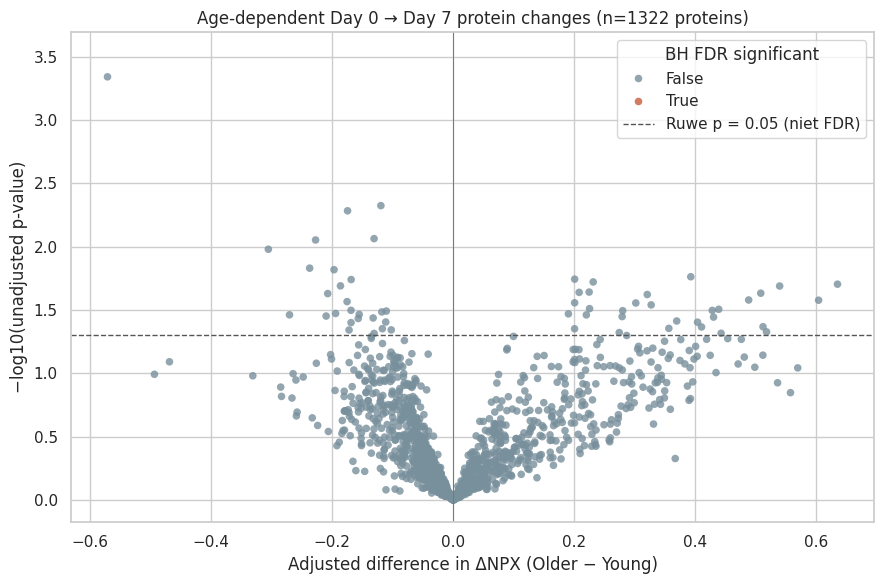

In [8]:
plot_data = results.copy()
plot_data['minus_log10_p'] = -np.log10(plot_data['p_value'].clip(lower=1e-300))

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=plot_data, x='beta_older', y='minus_log10_p',
    hue='fdr_significant', hue_order=[False, True],
    palette={False: '#78909C', True: '#C75B39'},
    alpha=0.8, s=30, linewidth=0, ax=ax
)
ax.axhline(-np.log10(0.05), color='#555555', linestyle='--', linewidth=1,
           label='Ruwe p = 0.05 (niet FDR)')
ax.axvline(0, color='#777777', linewidth=0.7)
ax.set(
    title=f'Age-dependent Day 0 → Day 7 protein changes (n={len(results)} proteins)',
    xlabel='Adjusted difference in ΔNPX (Older − Young)',
    ylabel='−log10(unadjusted p-value)'
)
ax.legend(title='BH FDR significant', loc='best')
plt.tight_layout()
plt.show()

## Stap 9 — Export en verslagnotities

De resultaten en figuur kunnen apart worden opgeslagen en gecommit. Bewaar de ruwe data niet per ongeluk in een publieke repository als jullie daar geen toestemming voor hebben.

**Voor in het verslag:** vermeld het exacte aantal geteste eiwitten, de vooraf gekozen filters, het contrast, de covariaten, het gebruikte model, de BH-correctie en het aantal significante eiwitten. Als er geen significant zijn, is dat een geldig en bespreekbaar resultaat. Discussieer ook mogelijke batch-effecten en de beperkte groep van 92 donoren.

In [9]:
out_dir = Path('results_part3')
out_dir.mkdir(exist_ok=True)
results.to_csv(out_dir / 'multiple_testing_results.csv', index=False)
fig.savefig(out_dir / 'volcano_plot.png', dpi=300, bbox_inches='tight')
print('Opgeslagen in:', out_dir.resolve())
print('Bestanden: multiple_testing_results.csv en volcano_plot.png')

Opgeslagen in: /mnt/data/results_part3
Bestanden: multiple_testing_results.csv en volcano_plot.png
